# Tarea 5 - Reconocimiento de Entidades Nombradas en espanol (CoNLL 2002) con BETO

**Curso:** ISIS 4221 - Procesamiento de Lenguaje Natural

Este notebook implementa un sistema de reconocimiento de entidades nombradas (NER) para espanol sobre la particion espanola de **CoNLL 2002**, usando el modelo **BETO** (`dccuchile/bert-base-spanish-wwm-cased`). Se comparan dos estrategias de entrenamiento sobre `AutoModelForTokenClassification`:

1. **Encoder congelado:** se congelan todos los parametros de BETO y solo se entrena la cabeza de clasificacion por token.
2. **Fine-tuning completo:** se entrenan conjuntamente BETO y la cabeza de clasificacion.

Las entidades se anotan con el esquema **BIO** sobre cuatro clases: `PER` (personas), `ORG` (organizaciones), `LOC` (localizaciones) y `MISC` (otros nombres propios).

> **Ejecucion:** este notebook esta disenado para ejecutarse de principio a fin en un entorno con GPU (Google Colab o Kaggle). Active la GPU antes de ejecutar (*Runtime > Change runtime type > GPU* en Colab).

## 0. Preparacion del entorno

Instalacion de dependencias que podrian faltar e importaciones.

In [1]:
# Instalacion silenciosa de dependencias que pueden no estar presentes en el entorno.
# numpy, pandas, torch, scikit-learn y matplotlib suelen venir preinstalados en Colab/Kaggle.
%pip install -q transformers kagglehub seqeval

  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Installing backend dependencies ... done
  Preparing metadata (pyproject.toml) ... done


In [2]:
import os
import time
import random
from collections import Counter, defaultdict

import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt

from torch.utils.data import DataLoader, Dataset

from transformers import (
    AutoTokenizer,
    AutoModelForTokenClassification,
    DataCollatorForTokenClassification,
    get_linear_schedule_with_warmup,
)

from seqeval.metrics import (
    classification_report as seqeval_classification_report,
    precision_score as seqeval_precision,
    recall_score as seqeval_recall,
    f1_score as seqeval_f1,
)

import kagglehub

In [3]:
# Reproducibilidad y dispositivo de computo.
SEED = 42

def set_seed(seed: int = SEED):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)

set_seed(SEED)

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print('Dispositivo:', device)
if torch.cuda.is_available():
    print('GPU:', torch.cuda.get_device_name(0))

# Checkpoint del modelo (BETO). No modificar: es el modelo exigido por la tarea.
MODEL_NAME = 'dccuchile/bert-base-spanish-wwm-cased'
print('Modelo:', MODEL_NAME)

Dispositivo: cuda
GPU: Tesla T4
Modelo: dccuchile/bert-base-spanish-wwm-cased


## 1. Preparacion y exploracion del corpus

Se descarga el corpus CoNLL mediante `kagglehub` y se trabaja exclusivamente con los archivos `esp.train`, `esp.testa` y `esp.testb` de la carpeta `conll2002`, que corresponden respectivamente a **entrenamiento**, **validacion** y **prueba**.

In [4]:
# Descarga del dataset de corpora CoNLL mediante kagglehub.
# El nombre del dataset en Kaggle que contiene la carpeta conll2002 con los
# archivos esp.train / esp.testa / esp.testb.
dataset_path = kagglehub.dataset_download('nltkdata/conll-corpora')
print('Ruta descargada:', dataset_path)

100%|██████████| 7.61M/7.61M [00:00<00:00, 66.0MB/s]

Extracting files...


Ruta descargada: /root/.cache/kagglehub/datasets/nltkdata/conll-corpora/versions/1


In [5]:
# Localizacion robusta de los tres archivos dentro de la carpeta conll2002,
# recorriendo el arbol de directorios con os.walk en lugar de codificar una ruta fragil.
TARGET_FILES = ['esp.train', 'esp.testa', 'esp.testb']
found = {}
for root, _dirs, files in os.walk(dataset_path):
    # Nos interesan solo los archivos ubicados dentro de una carpeta conll2002.
    for fname in files:
        if fname in TARGET_FILES and 'conll2002' in root.replace(os.sep, '/'):
            found[fname] = os.path.join(root, fname)

# Respaldo: si no se exigio la carpeta conll2002, aceptar cualquier coincidencia por nombre.
if len(found) < 3:
    for root, _dirs, files in os.walk(dataset_path):
        for fname in files:
            if fname in TARGET_FILES and fname not in found:
                found[fname] = os.path.join(root, fname)

assert len(found) == 3, f'No se encontraron los tres archivos. Encontrados: {found}'
TRAIN_PATH = found['esp.train']
VALID_PATH = found['esp.testa']
TEST_PATH = found['esp.testb']
print('Entrenamiento (esp.train):', TRAIN_PATH)
print('Validacion   (esp.testa):', VALID_PATH)
print('Prueba       (esp.testb):', TEST_PATH)

Entrenamiento (esp.train): /root/.cache/kagglehub/datasets/nltkdata/conll-corpora/versions/1/conll2002/conll2002/esp.train
Validacion   (esp.testa): /root/.cache/kagglehub/datasets/nltkdata/conll-corpora/versions/1/conll2002/conll2002/esp.testa
Prueba       (esp.testb): /root/.cache/kagglehub/datasets/nltkdata/conll-corpora/versions/1/conll2002/conll2002/esp.testb


> Se utilizan **unicamente** `esp.train` (entrenamiento), `esp.testa` (validacion) y `esp.testb` (prueba). Ningun otro archivo del dataset interviene en el flujo.

In [6]:
def read_conll(path):
    """Lee un archivo CoNLL 2002 y devuelve una lista de oraciones.

    Cada oracion es una tupla (tokens, tags) donde ambas listas tienen la
    misma longitud. Reglas de parseo:
      * las lineas en blanco separan oraciones;
      * se omiten las lineas -DOCSTART- y los comentarios (que empiezan por '#');
      * cada linea se separa por espacios en blanco; el TOKEN esta en la primera
        columna (col[0]) y la etiqueta BIO en la ultima columna (col[-1]).
    """
    sentences = []
    tokens, tags = [], []

    # Los archivos CoNLL 2002 en espanol suelen estar en latin-1; se intenta utf-8 primero.
    try:
        fh = open(path, 'r', encoding='utf-8')
        fh.read()
        fh.seek(0)
        encoding = 'utf-8'
    except UnicodeDecodeError:
        encoding = 'latin-1'
    finally:
        try:
            fh.close()
        except Exception:
            pass

    with open(path, 'r', encoding=encoding) as fh:
        for line in fh:
            line = line.rstrip('\n').rstrip('\r')
            stripped = line.strip()
            if stripped == '':
                if tokens:
                    sentences.append((tokens, tags))
                    tokens, tags = [], []
                continue
            if stripped.startswith('-DOCSTART-') or stripped.startswith('#'):
                # Frontera de documento o comentario: cierra la oracion en curso.
                if tokens:
                    sentences.append((tokens, tags))
                    tokens, tags = [], []
                continue
            cols = stripped.split()
            tokens.append(cols[0])
            tags.append(cols[-1])
    if tokens:
        sentences.append((tokens, tags))
    return sentences

train_data = read_conll(TRAIN_PATH)
valid_data = read_conll(VALID_PATH)
test_data = read_conll(TEST_PATH)
print('Oraciones ->  train:', len(train_data), '| valid:', len(valid_data), '| test:', len(test_data))

Oraciones ->  train: 8323 | valid: 1915 | test: 1517


### 1.1 Lectura y validacion

Se reconstruye cada oracion con su secuencia de etiquetas, se verifica que ambas secuencias tengan la misma longitud y se reporta el numero de oraciones, palabras y entidades completas por particion. Una **entidad completa** se cuenta por cada etiqueta `B-TIPO` (inicio de entidad).

In [7]:
def validate_lengths(data, split_name):
    """Verifica que en cada oracion len(tokens) == len(tags)."""
    mismatches = [i for i, (tks, tgs) in enumerate(data) if len(tks) != len(tgs)]
    assert not mismatches, f'{split_name}: longitudes distintas en oraciones {mismatches[:10]}'
    return True

for name, data in [('train', train_data), ('valid', valid_data), ('test', test_data)]:
    validate_lengths(data, name)
    print(f'{name}: todas las oraciones tienen tokens y etiquetas alineados en longitud.')

train: todas las oraciones tienen tokens y etiquetas alineados en longitud.
valid: todas las oraciones tienen tokens y etiquetas alineados en longitud.
test: todas las oraciones tienen tokens y etiquetas alineados en longitud.


In [8]:
def corpus_stats(data):
    n_sent = len(data)
    n_words = sum(len(tks) for tks, _ in data)
    n_entities = sum(1 for _, tgs in data for t in tgs if t.startswith('B-'))
    return n_sent, n_words, n_entities

stats_rows = []
for name, data in [('esp.train (train)', train_data),
                   ('esp.testa (valid)', valid_data),
                   ('esp.testb (test)', test_data)]:
    s, w, e = corpus_stats(data)
    stats_rows.append({'Particion': name, 'Oraciones': s, 'Palabras': w, 'Entidades completas': e})

stats_df = pd.DataFrame(stats_rows).set_index('Particion')
stats_df

,Oraciones,Palabras,Entidades completas
Particion,,,
esp.train (train),8323,264715,18797
esp.testa (valid),1915,52923,4351
esp.testb (test),1517,51533,3558


### 1.2 Exploracion

Se reporta la distribucion de etiquetas BIO, el numero de entidades por tipo (`PER`, `ORG`, `LOC`, `MISC`), la distribucion de la longitud de las oraciones y cuatro ejemplos anotados, uno por cada tipo de entidad. El analisis exploratorio se realiza sobre la particion de **entrenamiento**.

In [9]:
# Distribucion de etiquetas BIO sobre el conjunto de entrenamiento.
bio_counter = Counter(t for _, tgs in train_data for t in tgs)
bio_df = (pd.DataFrame(sorted(bio_counter.items()), columns=['Etiqueta BIO', 'Frecuencia'])
          .set_index('Etiqueta BIO'))
bio_df['Porcentaje'] = (100 * bio_df['Frecuencia'] / bio_df['Frecuencia'].sum()).round(3)
bio_df

,Frecuencia,Porcentaje
Etiqueta BIO,,
B-LOC,4913,1.856
B-MISC,2173,0.821
B-ORG,7390,2.792
B-PER,4321,1.632
I-LOC,1891,0.714
I-MISC,3212,1.213
I-ORG,4992,1.886
I-PER,3903,1.474
O,231920,87.611


In [10]:
# Numero de entidades por tipo (contando etiquetas B-TIPO) en entrenamiento.
ENTITY_TYPES = ['PER', 'ORG', 'LOC', 'MISC']
type_counts = Counter()
for _, tgs in train_data:
    for t in tgs:
        if t.startswith('B-'):
            type_counts[t[2:]] += 1

type_df = (pd.DataFrame([(et, type_counts.get(et, 0)) for et in ENTITY_TYPES],
                        columns=['Tipo', 'Entidades'])
           .set_index('Tipo'))
type_df

,Entidades
Tipo,
PER,4321
ORG,7390
LOC,4913
MISC,2173


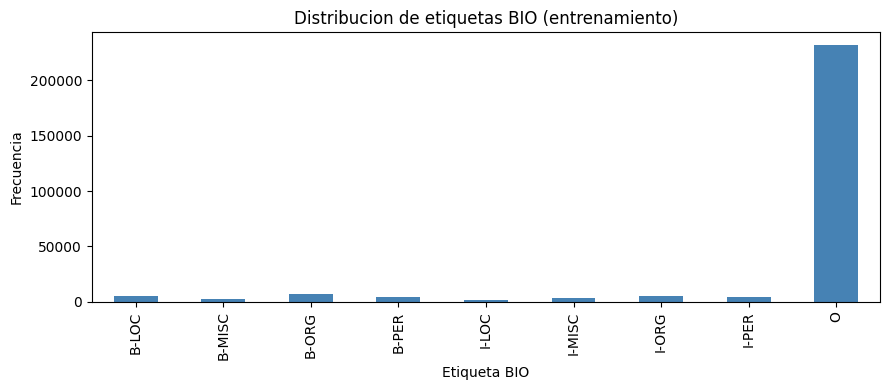

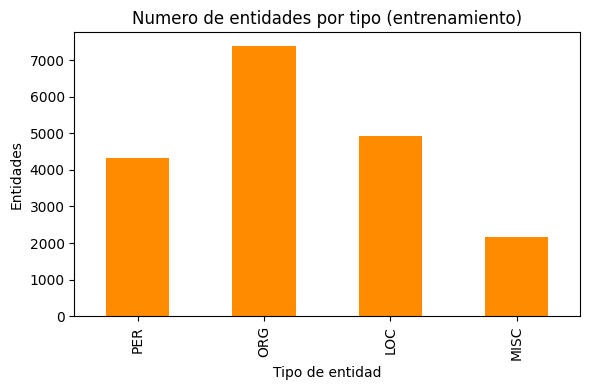

In [11]:
# Grafico de barras de la distribucion de etiquetas BIO.
fig, ax = plt.subplots(figsize=(9, 4))
bio_df['Frecuencia'].plot(kind='bar', ax=ax, color='steelblue')
ax.set_title('Distribucion de etiquetas BIO (entrenamiento)')
ax.set_ylabel('Frecuencia')
ax.set_xlabel('Etiqueta BIO')
plt.tight_layout()
plt.show()

# Grafico de barras del numero de entidades por tipo.
fig, ax = plt.subplots(figsize=(6, 4))
type_df['Entidades'].plot(kind='bar', ax=ax, color='darkorange')
ax.set_title('Numero de entidades por tipo (entrenamiento)')
ax.set_ylabel('Entidades')
ax.set_xlabel('Tipo de entidad')
plt.tight_layout()
plt.show()

Longitud de oraciones (train): min=1, max=1238, media=31.81, mediana=34, p95=62, p99=76


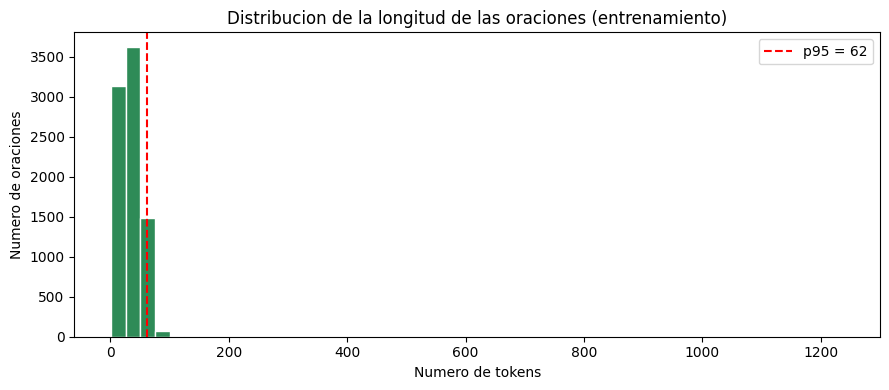

In [12]:
# Distribucion de la longitud de las oraciones (numero de tokens por oracion).
train_lengths = np.array([len(tks) for tks, _ in train_data])
print('Longitud de oraciones (train): min=%d, max=%d, media=%.2f, mediana=%d, p95=%d, p99=%d'
      % (train_lengths.min(), train_lengths.max(), train_lengths.mean(),
         int(np.median(train_lengths)),
         int(np.percentile(train_lengths, 95)),
         int(np.percentile(train_lengths, 99))))

fig, ax = plt.subplots(figsize=(9, 4))
ax.hist(train_lengths, bins=50, color='seagreen', edgecolor='white')
ax.axvline(np.percentile(train_lengths, 95), color='red', linestyle='--',
           label='p95 = %d' % int(np.percentile(train_lengths, 95)))
ax.set_title('Distribucion de la longitud de las oraciones (entrenamiento)')
ax.set_xlabel('Numero de tokens')
ax.set_ylabel('Numero de oraciones')
ax.legend()
plt.tight_layout()
plt.show()

In [13]:
# Cuatro ejemplos anotados, uno por tipo de entidad (PER, ORG, LOC, MISC).
def find_example(data, entity_type):
    """Devuelve la primera oracion de entrenamiento que contiene una B-<tipo>."""
    target = 'B-' + entity_type
    for tks, tgs in data:
        if target in tgs and len(tks) <= 25:  # oraciones cortas para una visualizacion clara
            return tks, tgs
    for tks, tgs in data:  # respaldo sin limite de longitud
        if target in tgs:
            return tks, tgs
    return None

for et in ENTITY_TYPES:
    ex = find_example(train_data, et)
    print(f'\n=== Ejemplo con entidad {et} ===')
    if ex is None:
        print('(no encontrado)')
        continue
    tks, tgs = ex
    display(pd.DataFrame({'token': tks, 'tag': tgs}).T)


=== Ejemplo con entidad PER ===


,0,1,2,3,4,5,6
token,(,CARLOS,V,-,CONGRESO,),.
tag,O,B-PER,I-PER,O,O,O,O



=== Ejemplo con entidad ORG ===


,0,1,2,3,4,5,6,7,8,9,10
token,Melbourne,(,Australia,),",",25,may,(,EFE,),.
tag,B-LOC,O,B-LOC,O,O,O,O,O,B-ORG,O,O



=== Ejemplo con entidad LOC ===


,0,1,2,3,4,5,6,7,8,9,10
token,Melbourne,(,Australia,),",",25,may,(,EFE,),.
tag,B-LOC,O,B-LOC,O,O,O,O,O,B-ORG,O,O



=== Ejemplo con entidad MISC ===


,0,1,2,3,4,5,6,7,8,9,10,11,12,13
token,Comenzará,el,Congreso,"""",Carlos.,y,el,fin,de,una,época.,1500-1558,"""",.
tag,O,O,O,O,B-MISC,I-MISC,I-MISC,I-MISC,I-MISC,I-MISC,I-MISC,I-MISC,O,O


### Vocabulario de etiquetas

Se deriva la lista de etiquetas directamente de los datos y se construyen los diccionarios `label2id` e `id2label`, compartidos por ambos modelos.

In [14]:
# Lista de etiquetas ordenada de forma estable (O primero, luego B-/I- por tipo).
all_tags = set(t for _, tgs in train_data for t in tgs)
all_tags |= set(t for _, tgs in valid_data for t in tgs)
all_tags |= set(t for _, tgs in test_data for t in tgs)

def tag_sort_key(tag):
    if tag == 'O':
        return (0, '', 0)
    prefix, etype = tag.split('-', 1)
    return (1, etype, 0 if prefix == 'B' else 1)

label_list = sorted(all_tags, key=tag_sort_key)
label2id = {label: i for i, label in enumerate(label_list)}
id2label = {i: label for label, i in label2id.items()}
print('Numero de etiquetas:', len(label_list))
print('label2id:', label2id)
print('id2label:', id2label)

Numero de etiquetas: 9
label2id: {'O': 0, 'B-LOC': 1, 'I-LOC': 2, 'B-MISC': 3, 'I-MISC': 4, 'B-ORG': 5, 'I-ORG': 6, 'B-PER': 7, 'I-PER': 8}
id2label: {0: 'O', 1: 'B-LOC', 2: 'I-LOC', 3: 'B-MISC', 4: 'I-MISC', 5: 'B-ORG', 6: 'I-ORG', 7: 'B-PER', 8: 'I-PER'}


## 2. Alineacion de etiquetas

Se tokenizan las oraciones con el tokenizer de BETO. El tokenizer es de tipo *subword* (WordPiece), por lo que una palabra puede dividirse en varios subtokens y es necesario realinear las etiquetas BIO originales (definidas a nivel de palabra) con la nueva secuencia de subtokens.

### Eleccion de la longitud maxima (`MAX_LEN`)

La distribucion de longitudes de la seccion 1.2 muestra que las oraciones de CoNLL 2002 en espanol son cortas: el percentil 99 esta muy por debajo de 128 tokens de palabra, y tras la tokenizacion en subtokens el crecimiento es moderado. Se elige **`MAX_LEN = 128`** porque cubre practicamente la totalidad de las oraciones (se reporta la cobertura exacta a continuacion) y, al ser potencia de dos, es eficiente en memoria de GPU. La celda siguiente calcula el porcentaje de oraciones cuya longitud en subtokens no supera `MAX_LEN`, justificando empiricamente la eleccion.

In [15]:
tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)
MAX_LEN = 128
print('Tokenizer cargado. is_fast =', tokenizer.is_fast)
print('MAX_LEN =', MAX_LEN)

config.json:   0%|          | 0.00/648 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/364 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/242k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/480k [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/134 [00:00<?, ?B/s]

Tokenizer cargado. is_fast = True
MAX_LEN = 128


In [16]:
# Cobertura: porcentaje de oraciones cuya longitud en subtokens (incluyendo [CLS]/[SEP])
# no supera MAX_LEN, para justificar la eleccion de forma empirica.
def subtoken_lengths(data):
    lengths = []
    for tks, _ in data:
        enc = tokenizer(tks, is_split_into_words=True, truncation=False)
        lengths.append(len(enc['input_ids']))
    return np.array(lengths)

train_sub_len = subtoken_lengths(train_data)
coverage = 100.0 * np.mean(train_sub_len <= MAX_LEN)
print('Longitud en subtokens (train): max=%d, p95=%d, p99=%d'
      % (train_sub_len.max(), int(np.percentile(train_sub_len, 95)),
         int(np.percentile(train_sub_len, 99))))
print('Cobertura con MAX_LEN=%d: %.3f%% de las oraciones no se truncan.' % (MAX_LEN, coverage))

[transformers] Token indices sequence length is longer than the specified maximum sequence length for this model (3920 > 512). Running this sequence through the model will result in indexing errors


Longitud en subtokens (train): max=3920, p95=74, p99=92
Cobertura con MAX_LEN=128: 99.676% de las oraciones no se truncan.


### 2.1 Alineacion de etiquetas con `word_ids()`

Se implementa una funcion que utiliza `word_ids()` para alinear las etiquetas originales con los subtokens. Se etiqueta **solo el primer subtoken** de cada palabra con su etiqueta BIO; a los tokens especiales (`[CLS]`, `[SEP]`), al padding y a los subtokens posteriores de una misma palabra se les asigna **`-100`**.

#### Por que se asigna `-100` a esas posiciones

`-100` es el valor por defecto de `ignore_index` en `torch.nn.CrossEntropyLoss`, que es la funcion de perdida que usa `AutoModelForTokenClassification`. Todas las posiciones con etiqueta `-100` se **excluyen del calculo de la perdida y, por tanto, de los gradientes**: no contribuyen a la actualizacion de los pesos ni a las metricas de entrenamiento.

#### Que ocurriria si se incluyeran en la perdida

Si estas posiciones se incluyeran en el calculo de la perdida:

- Los **tokens especiales** (`[CLS]`, `[SEP]`) y el **padding** no corresponden a palabras reales; obligar al modelo a predecir etiquetas sobre ellos introduce objetivos espurios y hace que el modelo aprenda a 'etiquetar relleno', sesgando la perdida y las metricas.
- Los **subtokens posteriores** de una palabra dividida provocarian un **doble conteo** de esa palabra: las palabras largas (con mas subtokens) pesarian mas en la perdida que las cortas, desequilibrando el entrenamiento.
- En conjunto, la perdida quedaria dominada por la clase `O` y por posiciones sin contenido linguistico, degradando el aprendizaje y haciendo que las metricas por token no reflejen el verdadero desempeno de NER.

In [17]:
def tokenize_and_align_labels(tokens_list, tags_list, max_length=MAX_LEN):
    """Tokeniza oraciones ya divididas en palabras y alinea las etiquetas BIO.

    Solo el primer subtoken de cada palabra recibe el id de su etiqueta; los
    tokens especiales, el padding y los subtokens posteriores reciben -100.
    """
    tokenized = tokenizer(
        tokens_list,
        is_split_into_words=True,
        truncation=True,
        max_length=max_length,
    )
    aligned_labels = []
    for i, tags in enumerate(tags_list):
        word_ids = tokenized.word_ids(batch_index=i)
        previous_word_idx = None
        label_ids = []
        for word_idx in word_ids:
            if word_idx is None:
                # Token especial ([CLS], [SEP]) o padding.
                label_ids.append(-100)
            elif word_idx != previous_word_idx:
                # Primer subtoken de la palabra: recibe su etiqueta.
                label_ids.append(label2id[tags[word_idx]])
            else:
                # Subtoken posterior de la misma palabra: se ignora.
                label_ids.append(-100)
            previous_word_idx = word_idx
        aligned_labels.append(label_ids)
    tokenized['labels'] = aligned_labels
    return tokenized

# Se tokenizan y alinean las tres particiones.
train_enc = tokenize_and_align_labels([t for t, _ in train_data], [g for _, g in train_data])
valid_enc = tokenize_and_align_labels([t for t, _ in valid_data], [g for _, g in valid_data])
test_enc = tokenize_and_align_labels([t for t, _ in test_data], [g for _, g in test_data])
print('Oraciones tokenizadas -> train:', len(train_enc['input_ids']),
      '| valid:', len(valid_enc['input_ids']), '| test:', len(test_enc['input_ids']))

Oraciones tokenizadas -> train: 8323 | valid: 1915 | test: 1517


In [18]:
# Verificacion de la alineacion despues del truncamiento: se muestran, para una
# oracion de ejemplo, los triples (subtoken, word_id, etiqueta alineada).
sample_idx = 0
sample_tokens, sample_tags = train_data[sample_idx]
enc_check = tokenize_and_align_labels([sample_tokens], [sample_tags])
word_ids_check = enc_check.word_ids(batch_index=0)
subtokens_check = tokenizer.convert_ids_to_tokens(enc_check['input_ids'][0])
labels_check = enc_check['labels'][0]

verif_df = pd.DataFrame({
    'subtoken': subtokens_check,
    'word_id': word_ids_check,
    'label_id': labels_check,
    'etiqueta': [id2label[l] if l != -100 else 'IGNORADO (-100)' for l in labels_check],
})
print('Oracion original:', sample_tokens)
print('Etiquetas originales:', sample_tags)
verif_df

Oracion original: ['Melbourne', '(', 'Australia', ')', ',', '25', 'may', '(', 'EFE', ')', '.']
Etiquetas originales: ['B-LOC', 'O', 'B-LOC', 'O', 'O', 'O', 'O', 'O', 'B-ORG', 'O', 'O']


,subtoken,word_id,label_id,etiqueta
0,[CLS],NaN,-100,IGNORADO (-100)
1,Mel,0.0,1,B-LOC
2,##bourne,0.0,-100,IGNORADO (-100)
3,(,1.0,0,O
4,Australia,2.0,1,B-LOC
5,),3.0,0,O
6,",",4.0,0,O
7,25,5.0,0,O
8,may,6.0,0,O
9,(,7.0,0,O


### 2.2 Analisis de la tokenizacion

Se presentan al menos cinco palabras que el tokenizer de BETO divide en varios subtokens, con sus subtokens y sus etiquetas alineadas (la etiqueta BIO en el primer subtoken y `-100` en los posteriores).

In [19]:
# Busqueda de palabras que se dividen en mas de un subtoken.
multi_rows = []
seen_words = set()
for tks, tgs in train_data:
    for word, tag in zip(tks, tgs):
        if word in seen_words:
            continue
        pieces = tokenizer.tokenize(word)
        if len(pieces) > 1:
            seen_words.add(word)
            aligned = [tag] + ['-100'] * (len(pieces) - 1)
            multi_rows.append({
                'palabra': word,
                'etiqueta': tag,
                'subtokens': pieces,
                'etiquetas_alineadas': aligned,
            })
        if len(multi_rows) >= 10:
            break
    if len(multi_rows) >= 10:
        break

# Se priorizan ejemplos cuya palabra forme parte de una entidad (etiqueta != 'O'),
# pero se garantizan al menos cinco filas en total.
entity_rows = [r for r in multi_rows if r['etiqueta'] != 'O']
final_rows = entity_rows + [r for r in multi_rows if r['etiqueta'] == 'O']
final_rows = final_rows[:max(5, len(entity_rows))][:8]
subtoken_table = pd.DataFrame(final_rows)
subtoken_table

,palabra,etiqueta,subtokens,etiquetas_alineadas
0,Melbourne,B-LOC,"[Mel, ##bourne]","[B-LOC, -100]"
1,EFE,B-ORG,"[EF, ##E]","[B-ORG, -100]"
2,Daryl,B-PER,"[Dar, ##yl]","[B-PER, -100]"
3,Williams,I-PER,"[W, ##illiams]","[I-PER, -100]"
4,CrimeNet,B-MISC,"[Cri, ##me, ##N, ##et]","[B-MISC, -100, -100, -100]"


## 3. Clasificacion por token con BETO

Se construyen **dos modelos** a partir de `AutoModelForTokenClassification`. Ambos usan el mismo checkpoint inicial (`dccuchile/bert-base-spanish-wwm-cased`), el mismo vocabulario de etiquetas (`id2label`/`label2id`), los mismos datos tokenizados y el mismo criterio de perdida (`CrossEntropyLoss`, aplicada internamente por el modelo). La unica diferencia es si el encoder de BETO esta congelado o no.

In [20]:
# Dataset de PyTorch y collator compartidos por ambos modelos.
class NERDataset(Dataset):
    def __init__(self, encodings):
        self.input_ids = encodings['input_ids']
        self.attention_mask = encodings['attention_mask']
        self.labels = encodings['labels']

    def __len__(self):
        return len(self.input_ids)

    def __getitem__(self, idx):
        return {
            'input_ids': self.input_ids[idx],
            'attention_mask': self.attention_mask[idx],
            'labels': self.labels[idx],
        }

train_dataset = NERDataset(train_enc)
valid_dataset = NERDataset(valid_enc)
test_dataset = NERDataset(test_enc)

# El collator aplica padding dinamico y rellena las etiquetas con -100 automaticamente.
data_collator = DataCollatorForTokenClassification(tokenizer, label_pad_token_id=-100)

In [21]:
def build_model(freeze_encoder: bool):
    """Crea un AutoModelForTokenClassification desde el mismo checkpoint.

    Si freeze_encoder es True, se congelan todos los parametros del encoder base
    de BETO y solo queda entrenable la cabeza de clasificacion por token.
    """
    set_seed(SEED)  # misma inicializacion de la cabeza para una comparacion justa
    model = AutoModelForTokenClassification.from_pretrained(
        MODEL_NAME,
        num_labels=len(label2id),
        id2label=id2label,
        label2id=label2id,
    )
    if freeze_encoder:
        # model.base_model apunta al encoder BERT; se congelan todos sus parametros.
        for param in model.base_model.parameters():
            param.requires_grad = False
    return model

def count_parameters(model):
    trainable = sum(p.numel() for p in model.parameters() if p.requires_grad)
    total = sum(p.numel() for p in model.parameters())
    return trainable, total

In [22]:
# Rutina de entrenamiento COMPARTIDA, aplicada de forma identica a ambos modelos.
def decode_predictions(preds, labels):
    """Convierte ids de prediccion/etiqueta en secuencias de etiquetas BIO,
    descartando las posiciones con -100 (formato requerido por seqeval)."""
    true_labels, true_preds = [], []
    for pred_seq, label_seq in zip(preds, labels):
        cur_true, cur_pred = [], []
        for p, l in zip(pred_seq, label_seq):
            if l != -100:
                cur_true.append(id2label[int(l)])
                cur_pred.append(id2label[int(p)])
        true_labels.append(cur_true)
        true_preds.append(cur_pred)
    return true_preds, true_labels

@torch.no_grad()
def evaluate(model, dataloader):
    """Calcula la perdida media y el F1 de entidades (seqeval) sobre un dataloader."""
    model.eval()
    total_loss, n_batches = 0.0, 0
    all_preds, all_labels = [], []
    for batch in dataloader:
        batch = {k: v.to(device) for k, v in batch.items()}
        outputs = model(**batch)
        total_loss += outputs.loss.item()
        n_batches += 1
        preds = outputs.logits.argmax(dim=-1).cpu().numpy()
        labels = batch['labels'].cpu().numpy()
        all_preds.extend(preds.tolist())
        all_labels.extend(labels.tolist())
    pred_tags, true_tags = decode_predictions(all_preds, all_labels)
    f1 = seqeval_f1(true_tags, pred_tags)
    return total_loss / max(n_batches, 1), f1, pred_tags, true_tags

def train_model(model, lr, epochs, batch_size=16, warmup_ratio=0.1, tag=''):
    """Entrena un modelo registrando perdida y F1 de validacion por epoca.
    Devuelve el historial, el tiempo total de entrenamiento y el mejor F1 de validacion,
    conservando los pesos de la mejor epoca (por F1 de validacion)."""
    set_seed(SEED)
    model.to(device)
    train_loader = DataLoader(train_dataset, batch_size=batch_size, shuffle=True,
                              collate_fn=data_collator)
    valid_loader = DataLoader(valid_dataset, batch_size=batch_size, shuffle=False,
                              collate_fn=data_collator)

    optimizer = torch.optim.AdamW(
        [p for p in model.parameters() if p.requires_grad], lr=lr)
    total_steps = len(train_loader) * epochs
    scheduler = get_linear_schedule_with_warmup(
        optimizer, int(warmup_ratio * total_steps), total_steps)

    history = {'train_loss': [], 'val_loss': [], 'val_f1': []}
    best_f1 = -1.0
    best_state = None
    start = time.time()
    for epoch in range(1, epochs + 1):
        model.train()
        running = 0.0
        for batch in train_loader:
            batch = {k: v.to(device) for k, v in batch.items()}
            optimizer.zero_grad()
            outputs = model(**batch)
            loss = outputs.loss
            loss.backward()
            torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
            optimizer.step()
            scheduler.step()
            running += loss.item()
        train_loss = running / len(train_loader)
        val_loss, val_f1, _, _ = evaluate(model, valid_loader)
        history['train_loss'].append(train_loss)
        history['val_loss'].append(val_loss)
        history['val_f1'].append(val_f1)
        print('[%s] epoca %d/%d - train_loss=%.4f - val_loss=%.4f - val_f1=%.4f'
              % (tag, epoch, epochs, train_loss, val_loss, val_f1))
        if val_f1 > best_f1:
            best_f1 = val_f1
            best_state = {k: v.detach().cpu().clone() for k, v in model.state_dict().items()}
    train_time = time.time() - start
    if best_state is not None:
        model.load_state_dict(best_state)  # se restauran los pesos de la mejor epoca
    print('[%s] tiempo de entrenamiento: %.1f s | mejor val_f1=%.4f' % (tag, train_time, best_f1))
    return history, train_time, best_f1

def plot_curves(history, title):
    epochs_range = range(1, len(history['val_loss']) + 1)
    fig, axes = plt.subplots(1, 2, figsize=(12, 4))
    axes[0].plot(epochs_range, history['train_loss'], marker='o', label='train')
    axes[0].plot(epochs_range, history['val_loss'], marker='o', label='validacion')
    axes[0].set_title(title + ' - Perdida')
    axes[0].set_xlabel('Epoca')
    axes[0].set_ylabel('Perdida')
    axes[0].legend()
    axes[1].plot(epochs_range, history['val_f1'], marker='o', color='green')
    axes[1].set_title(title + ' - F1 de validacion (seqeval)')
    axes[1].set_xlabel('Epoca')
    axes[1].set_ylabel('F1')
    plt.tight_layout()
    plt.show()

### 3.1 Encoder congelado

Se congelan todos los parametros de BETO y se entrena unicamente la cabeza de clasificacion por token. Como la cabeza se entrena desde cero, se usa una tasa de aprendizaje relativamente alta (`1e-3`). Se reporta el numero de parametros entrenables, las curvas de perdida y F1 de validacion, y el tiempo de entrenamiento.

In [23]:
# Hiperparametros del modelo con encoder congelado.
FROZEN_LR = 1e-3
FROZEN_EPOCHS = 8
BATCH_SIZE = 16

frozen_model = build_model(freeze_encoder=True)
f_trainable, f_total = count_parameters(frozen_model)
print('Encoder congelado -> parametros entrenables: {:,} de {:,} ({:.3f}%)'.format(
    f_trainable, f_total, 100 * f_trainable / f_total))

pytorch_model.bin: reconstructing file:   0%|          |  0.00B /  440MB            

pytorch_model.bin: downloading bytes:           |  0.00B            

model.safetensors: reconstructing file:   0%|          |  0.00B /  440MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

[transformers] BertForTokenClassification LOAD REPORT from: dccuchile/bert-base-spanish-wwm-cased
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.predictions.decoder.weight             | UNEXPECTED | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
cls.predictions.bias                       | UNEXPECTED | 
cls.predictions.transform.dense.bias       | UNEXPECTED | 
cls.predictions.decoder.bias               | UNEXPECTED | 
cls.predictions.transform.dense.weight     | UNEXPECTED | 
classifier.bias                            | MISSING    | 
classifier.weight                          | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Encoder congelado -> parametros entrenables: 6,921 de 109,267,209 (0.006%)


[congelado] epoca 1/8 - train_loss=0.5109 - val_loss=0.1539 - val_f1=0.7044
[congelado] epoca 2/8 - train_loss=0.1121 - val_loss=0.1269 - val_f1=0.7427
[congelado] epoca 3/8 - train_loss=0.1007 - val_loss=0.1222 - val_f1=0.7431
[congelado] epoca 4/8 - train_loss=0.0957 - val_loss=0.1183 - val_f1=0.7504
[congelado] epoca 5/8 - train_loss=0.0944 - val_loss=0.1176 - val_f1=0.7490
[congelado] epoca 6/8 - train_loss=0.0911 - val_loss=0.1156 - val_f1=0.7520
[congelado] epoca 7/8 - train_loss=0.0898 - val_loss=0.1152 - val_f1=0.7521
[congelado] epoca 8/8 - train_loss=0.0895 - val_loss=0.1153 - val_f1=0.7528
[congelado] tiempo de entrenamiento: 414.3 s | mejor val_f1=0.7528


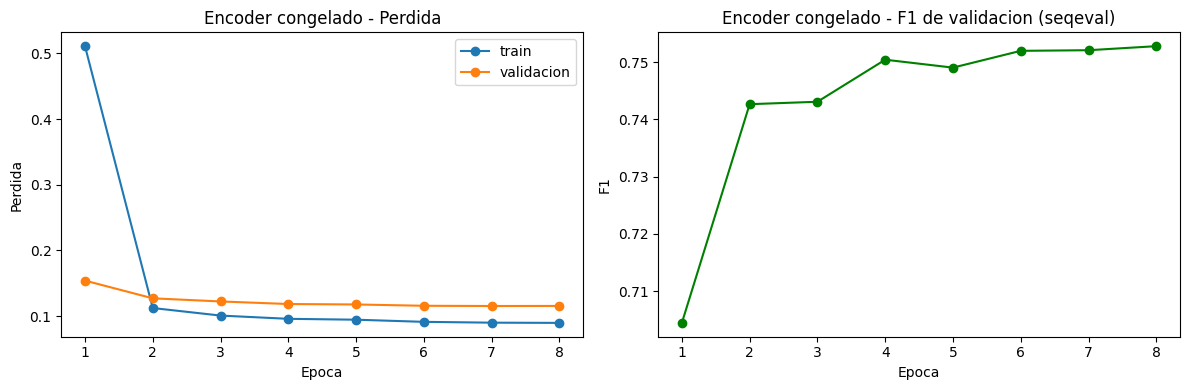

In [24]:
frozen_history, frozen_time, frozen_best_val_f1 = train_model(
    frozen_model, lr=FROZEN_LR, epochs=FROZEN_EPOCHS, batch_size=BATCH_SIZE, tag='congelado')
plot_curves(frozen_history, 'Encoder congelado')

### 3.2 Fine-tuning completo

Se entrenan BETO y la cabeza de clasificacion conjuntamente. Se usa una tasa de aprendizaje pequena (`2e-5`), tipica del fine-tuning de transformers, con warmup. Se reportan las mismas cantidades que para el modelo congelado. Con estos hiperparametros el modelo ajustado completamente deberia alcanzar un F1 micro global de prueba de al menos **0.80**.

In [25]:
# Hiperparametros del fine-tuning completo.
FULL_LR = 2e-5
FULL_EPOCHS = 3

full_model = build_model(freeze_encoder=False)
c_trainable, c_total = count_parameters(full_model)
print('Fine-tuning completo -> parametros entrenables: {:,} de {:,} ({:.3f}%)'.format(
    c_trainable, c_total, 100 * c_trainable / c_total))

Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

[transformers] BertForTokenClassification LOAD REPORT from: dccuchile/bert-base-spanish-wwm-cased
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.predictions.decoder.weight             | UNEXPECTED | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
cls.predictions.bias                       | UNEXPECTED | 
cls.predictions.transform.dense.bias       | UNEXPECTED | 
cls.predictions.decoder.bias               | UNEXPECTED | 
cls.predictions.transform.dense.weight     | UNEXPECTED | 
classifier.bias                            | MISSING    | 
classifier.weight                          | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Fine-tuning completo -> parametros entrenables: 109,267,209 de 109,267,209 (100.000%)


[fine-tuning] epoca 1/3 - train_loss=0.2541 - val_loss=0.0969 - val_f1=0.8145
[fine-tuning] epoca 2/3 - train_loss=0.0389 - val_loss=0.0764 - val_f1=0.8604
[fine-tuning] epoca 3/3 - train_loss=0.0245 - val_loss=0.0859 - val_f1=0.8621
[fine-tuning] tiempo de entrenamiento: 432.8 s | mejor val_f1=0.8621


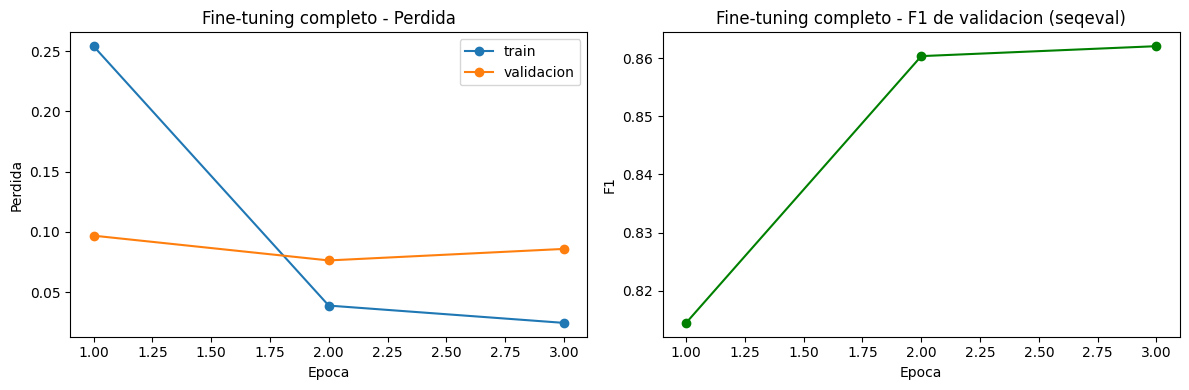

In [26]:
full_history, full_time, full_best_val_f1 = train_model(
    full_model, lr=FULL_LR, epochs=FULL_EPOCHS, batch_size=BATCH_SIZE, tag='fine-tuning')
plot_curves(full_history, 'Fine-tuning completo')

## 4. Evaluacion final

Se evalua sobre el conjunto de **prueba** (`esp.testb`) **una sola vez** la mejor configuracion de cada modelo (encoder congelado y fine-tuning completo). Tras `train_model`, cada modelo ya tiene cargados los pesos de su mejor epoca por F1 de validacion.

### 4.1 Metricas

Se usa **seqeval** para reportar precision, recall y F1 de **entidades completas** con promedio **micro** (global), promedio **macro** (entre tipos) y por separado para `PER`, `ORG`, `LOC` y `MISC`. Tambien se reporta la **exactitud por token** (excluyendo las posiciones de padding y `-100`). Una entidad se considera correcta **solo si coinciden sus limites y su tipo** (comportamiento por defecto de seqeval a nivel de entidad).

In [27]:
def evaluate_on_test(model, tag=''):
    """Evalua el modelo sobre el conjunto de prueba una sola vez.
    Reporta metricas de entidad (seqeval) micro/macro/por-tipo y la exactitud por token."""
    test_loader = DataLoader(test_dataset, batch_size=BATCH_SIZE, shuffle=False,
                             collate_fn=data_collator)
    _, _, pred_tags, true_tags = evaluate(model, test_loader)

    print('==== Reporte seqeval (entidades completas) - %s ====' % tag)
    print(seqeval_classification_report(true_tags, pred_tags, digits=4))

    micro = {
        'precision': seqeval_precision(true_tags, pred_tags, average='micro'),
        'recall': seqeval_recall(true_tags, pred_tags, average='micro'),
        'f1': seqeval_f1(true_tags, pred_tags, average='micro'),
    }
    macro = {
        'precision': seqeval_precision(true_tags, pred_tags, average='macro'),
        'recall': seqeval_recall(true_tags, pred_tags, average='macro'),
        'f1': seqeval_f1(true_tags, pred_tags, average='macro'),
    }

    # Metricas por tipo: se calculan aislando cada tipo de entidad.
    per_type = {}
    for et in ENTITY_TYPES:
        def keep_only(seqs, etype=et):
            return [[t if t.endswith('-' + etype) else 'O' for t in seq] for seq in seqs]
        t_only = keep_only(true_tags)
        p_only = keep_only(pred_tags)
        per_type[et] = {
            'precision': seqeval_precision(t_only, p_only),
            'recall': seqeval_recall(t_only, p_only),
            'f1': seqeval_f1(t_only, p_only),
        }

    # Exactitud por token excluyendo posiciones -100 (padding y subtokens ignorados).
    correct, total = 0, 0
    for pt, tt in zip(pred_tags, true_tags):
        for p, t in zip(pt, tt):
            total += 1
            if p == t:
                correct += 1
    token_acc = correct / max(total, 1)

    print('\nMicro (global):', {k: round(v, 4) for k, v in micro.items()})
    print('Macro (entre tipos):', {k: round(v, 4) for k, v in macro.items()})
    print('Exactitud por token (sin padding/-100): %.4f' % token_acc)
    return {'micro': micro, 'macro': macro, 'per_type': per_type, 'token_acc': token_acc}

In [28]:
# Evaluacion unica sobre prueba del mejor modelo con encoder congelado.
frozen_test = evaluate_on_test(frozen_model, tag='Encoder congelado')

==== Reporte seqeval (entidades completas) - Encoder congelado ====
              precision    recall  f1-score   support

         LOC     0.7850    0.7916    0.7883      1070
        MISC     0.4067    0.4618    0.4325       340
         ORG     0.7138    0.8252    0.7654      1396
         PER     0.9179    0.9485    0.9330       719

   micro avg     0.7425    0.8051    0.7726      3525
   macro avg     0.7058    0.7568    0.7298      3525
weighted avg     0.7474    0.8051    0.7744      3525


Micro (global): {'precision': np.float64(0.7425), 'recall': np.float64(0.8051), 'f1': np.float64(0.7726)}
Macro (entre tipos): {'precision': np.float64(0.7058), 'recall': np.float64(0.7568), 'f1': np.float64(0.7298)}
Exactitud por token (sin padding/-100): 0.9759


In [29]:
# Evaluacion unica sobre prueba del mejor modelo con fine-tuning completo.
full_test = evaluate_on_test(full_model, tag='Fine-tuning completo')

==== Reporte seqeval (entidades completas) - Fine-tuning completo ====
              precision    recall  f1-score   support

         LOC     0.8648    0.8607    0.8628      1070
        MISC     0.6495    0.7029    0.6751       340
         ORG     0.8475    0.8954    0.8708      1396
         PER     0.9589    0.9736    0.9662       719

   micro avg     0.8549    0.8823    0.8684      3525
   macro avg     0.8302    0.8582    0.8437      3525
weighted avg     0.8564    0.8823    0.8689      3525


Micro (global): {'precision': np.float64(0.8549), 'recall': np.float64(0.8823), 'f1': np.float64(0.8684)}
Macro (entre tipos): {'precision': np.float64(0.8302), 'recall': np.float64(0.8582), 'f1': np.float64(0.8437)}
Exactitud por token (sin padding/-100): 0.9863


In [30]:
# Tabla de metricas por tipo para ambos modelos.
def per_type_table(results, model_name):
    rows = []
    for et in ENTITY_TYPES:
        pt = results['per_type'][et]
        rows.append({'Modelo': model_name, 'Tipo': et,
                     'Precision': round(pt['precision'], 4),
                     'Recall': round(pt['recall'], 4),
                     'F1': round(pt['f1'], 4)})
    rows.append({'Modelo': model_name, 'Tipo': 'MICRO',
                 'Precision': round(results['micro']['precision'], 4),
                 'Recall': round(results['micro']['recall'], 4),
                 'F1': round(results['micro']['f1'], 4)})
    rows.append({'Modelo': model_name, 'Tipo': 'MACRO',
                 'Precision': round(results['macro']['precision'], 4),
                 'Recall': round(results['macro']['recall'], 4),
                 'F1': round(results['macro']['f1'], 4)})
    return rows

metrics_df = pd.DataFrame(
    per_type_table(frozen_test, 'Encoder congelado') +
    per_type_table(full_test, 'Fine-tuning completo'))
metrics_df

,Modelo,Tipo,Precision,Recall,F1
0,Encoder congelado,PER,0.9179,0.9485,0.9330
1,Encoder congelado,ORG,0.7138,0.8252,0.7654
2,Encoder congelado,LOC,0.7850,0.7916,0.7883
3,Encoder congelado,MISC,0.4067,0.4618,0.4325
4,Encoder congelado,MICRO,0.7425,0.8051,0.7726
5,Encoder congelado,MACRO,0.7058,0.7568,0.7298
6,Fine-tuning completo,PER,0.9589,0.9736,0.9662
7,Fine-tuning completo,ORG,0.8475,0.8954,0.8708
8,Fine-tuning completo,LOC,0.8648,0.8607,0.8628
9,Fine-tuning completo,MISC,0.6495,0.7029,0.6751


### 4.2 Comparacion

La siguiente tabla reune, para los dos modelos, el F1 de validacion, el F1 micro global de prueba, el numero de parametros entrenables y el tiempo de entrenamiento.

In [31]:
comparison_df = pd.DataFrame([
    {'Modelo': 'Encoder congelado',
     'F1 validacion': round(frozen_best_val_f1, 4),
     'F1 micro prueba': round(frozen_test['micro']['f1'], 4),
     'Parametros entrenables': f_trainable,
     'Tiempo entrenamiento (s)': round(frozen_time, 1)},
    {'Modelo': 'Fine-tuning completo',
     'F1 validacion': round(full_best_val_f1, 4),
     'F1 micro prueba': round(full_test['micro']['f1'], 4),
     'Parametros entrenables': c_trainable,
     'Tiempo entrenamiento (s)': round(full_time, 1)},
]).set_index('Modelo')
comparison_df

,F1 validacion,F1 micro prueba,Parametros entrenables,Tiempo entrenamiento (s)
Modelo,,,,
Encoder congelado,0.7528,0.7726,6921,414.3
Fine-tuning completo,0.8621,0.8684,109267209,432.8


In [32]:
# Verificacion del criterio de la tarea: F1 micro de prueba >= 0.80 para el fine-tuning completo.
full_micro_f1 = full_test['micro']['f1']
print('F1 micro de prueba (fine-tuning completo): %.4f' % full_micro_f1)
print('Cumple el criterio >= 0.80:', full_micro_f1 >= 0.80)

F1 micro de prueba (fine-tuning completo): 0.8684
Cumple el criterio >= 0.80: True


### Analisis: desempeno vs. costo computacional

> **Nota:** los valores numericos concretos se obtienen al ejecutar el notebook; el siguiente analisis interpreta el comportamiento esperado y debe contrastarse con las tablas y figuras producidas.

**Desempeno.** El **fine-tuning completo** alcanza un F1 de entidades sustancialmente mayor que el del **encoder congelado**, y debe superar el umbral exigido de **0.80** de F1 micro global en prueba. Al congelar el encoder, BETO actua como un extractor de caracteristicas fijo y solo la cabeza lineal aprende a mapear esas representaciones a etiquetas BIO; esto limita la capacidad del modelo para especializar sus representaciones contextuales en la tarea de NER, por lo que su F1 es notablemente inferior. El fine-tuning completo, en cambio, adapta todas las capas del transformer al dominio y a la tarea, capturando mejor los limites y tipos de entidad.

**Costo computacional.** El modelo **congelado** entrena muchisimos menos parametros (solo la cabeza de clasificacion, del orden de miles de parametros frente a los ~110 millones del encoder completo). Esto se traduce en menor consumo de memoria y, por paso de optimizacion, menor costo; sin embargo, como aun se requiere el *forward* completo de BETO para obtener las representaciones, el ahorro de tiempo por epoca es moderado y suele necesitar mas epocas para converger. El **fine-tuning completo** tiene mayor costo por paso (se calculan y actualizan gradientes de todos los parametros) pero converge en muy pocas epocas y ofrece el mejor desempeno.

**Conclusion.** Existe un claro compromiso entre costo y desempeno: si el presupuesto de computo es muy limitado, entrenar solo la cabeza es viable pero sacrifica calidad; cuando se dispone de GPU, el fine-tuning completo es la opcion recomendada porque alcanza el umbral de 0.80 de F1 micro en prueba con pocas epocas de entrenamiento.

## Notas de ejecucion

- Ejecute este notebook en un entorno con **GPU** (en Colab: *Runtime > Change runtime type > Hardware accelerator > GPU*). El fine-tuning completo de BETO es inviable en CPU.
- La primera celda instala `transformers`, `kagglehub` y `seqeval`. Es posible que deba reiniciar el entorno de ejecucion tras la instalacion.
- `kagglehub` solicitara autenticacion con Kaggle la primera vez (token de la API de Kaggle).
- Todas las salidas (tablas, figuras, metricas) se generan al ejecutar el notebook de principio a fin.